<a href="https://colab.research.google.com/github/rudrakj/Assist/blob/master/Youtube_NLP_Text_Representaion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# !pip install sklearn -q
# !pip install spacy -q
# !python -m spacy download en_core_web_sm

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from sklearn import metrics

import string
import spacy
np.random.seed(42)

In [2]:
data = pd.read_csv("train.csv", engine="python")
data.head()

,comment_text,toxic
0,Explanation\nWhy the edits made under my usern...,0.0
1,D'aww! He matches this background colour I'm s...,0.0
2,"Hey man, I'm really not trying to edit war. It...",0.0
3,"""\nMore\nI can't make any real suggestions on ...",0.0
4,"You, sir, are my hero. Any chance you remember...",0.0


In [3]:
nlp = spacy.load("en_core_web_sm")
stop_words = nlp.Defaults.stop_words
print(stop_words)

{'formerly', 'forty', 'during', 'whither', 'a', '’re', 'done', 'it', 'nevertheless', 'seemed', 'itself', 'most', 'him', 'above', 'nine', 'so', 'fifteen', 'me', 'into', 'around', 'first', 'through', 'some', 'we', 'whatever', 'where', 'hence', 'nobody', 'such', 'who', 'to', 'they', 'everyone', 'whereupon', 'below', 'further', 'show', 'namely', 'ca', 'throughout', 'something', 'too', 'indeed', 'than', 'in', 'therein', 'now', 'among', 'former', 'serious', 'is', 'her', 'latterly', 'mine', 'about', 'whereafter', 'must', 'that', 'himself', 'only', 'become', 'alone', 'put', 'how', 'being', '‘s', 'own', 'might', 'has', 'eleven', 'cannot', 'whereas', 'thereupon', 'any', 'quite', 'however', 'when', 'bottom', 'your', 'eight', "'ve", 'whole', 'next', 'much', 'by', 'every', 'amongst', 'not', 'with', 'using', 'beyond', 'always', 'herein', 'latter', '’ll', 'or', 'front', 'n‘t', 'three', 'seem', 'per', 'did', 'do', 'she', 'themselves', 'hers', 'along', 'he', 'though', 'under', 'whether', 'often', "'ll"

In [4]:
punctuations = string.punctuation
print(punctuations)

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [5]:
# Creating our tokenizer function
def spacy_tokenizer(sentence):
    # Creating our token object, which is used to create documents with linguistic annotations.
    doc = nlp(sentence)



    # print(doc)
    # print(type(doc))

    # Lemmatizing each token and converting each token into lowercase
    mytokens = [ word.lemma_.lower().strip() for word in doc ]

    # print(mytokens)

    # Removing stop words
    mytokens = [ word for word in mytokens if word not in stop_words and word not in punctuations ]

    # return preprocessed list of tokens
    return mytokens

In [6]:
sentence = "I am eating apple ?"
spacy_tokenizer(sentence)

['eat', 'apple']

In [7]:
count_vector = CountVectorizer(tokenizer = spacy_tokenizer)
# tfidf_vector = TfidfVectorizer(tokenizer = spacy_tokenizer)

In [8]:
count_vector.fit_transform(["I am eating apple, I like apple","I am playing cricket"]).toarray()

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


array([[2, 0, 1, 1, 0],
       [0, 1, 0, 0, 1]])

In [9]:
count_vector.get_feature_names_out()

array(['apple', 'cricket', 'eat', 'like', 'play'], dtype=object)

In [10]:
count_vector.vocabulary_

{'eat': 2, 'apple': 0, 'like': 3, 'play': 4, 'cricket': 1}

In [12]:
data[data['comment_text'].isna()]

,comment_text,toxic
499,NaN,NaN
500,NaN,NaN
501,NaN,NaN
502,NaN,NaN
503,NaN,NaN
...,...,...
159566,NaN,NaN
159567,NaN,NaN
159568,NaN,NaN
159569,NaN,NaN


In [13]:
data.dropna(inplace=True)

In [14]:
data.duplicated().sum()

np.int64(0)

In [15]:
data.drop_duplicates(inplace=True)

In [28]:
data['comment_text'] = data['comment_text'].str.replace('"','',regex=True)

<Axes: xlabel='toxic', ylabel='count'>

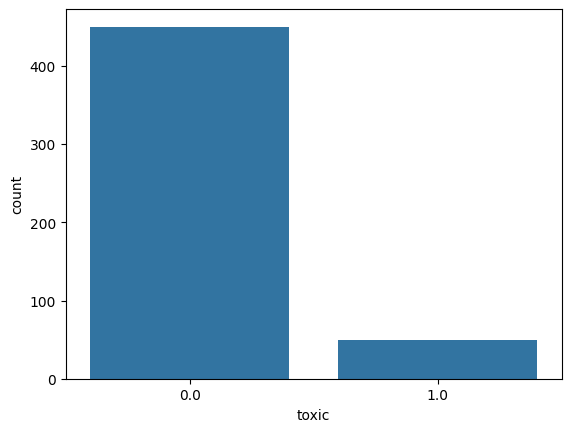

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=data, x ='toxic')

In [33]:
data['word_count'] = data['comment_text'].apply(lambda x: len(x.split()))
data.head()

,comment_text,toxic,word_count
0,Explanation\nWhy the edits made under my usern...,0.0,43
1,D'aww! He matches this background colour I'm s...,0.0,17
2,"Hey man, I'm really not trying to edit war. It...",0.0,42
3,\nMore\nI can't make any real suggestions on i...,0.0,111
4,"You, sir, are my hero. Any chance you remember...",0.0,13


In [34]:
data['word_count'].describe()

,word_count
count,499.000000
mean,63.673347
std,95.971316
min,4.000000
25%,16.000000
50%,35.000000
75%,76.000000
max,1052.000000


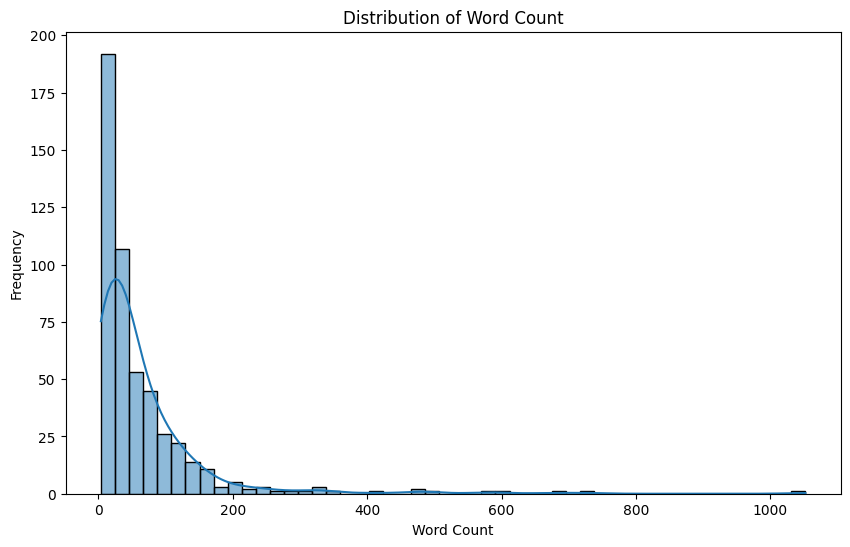

In [35]:
plt.figure(figsize=(10, 6))
sns.histplot(data['word_count'], bins=50, kde=True)
plt.title('Distribution of Word Count')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.show()

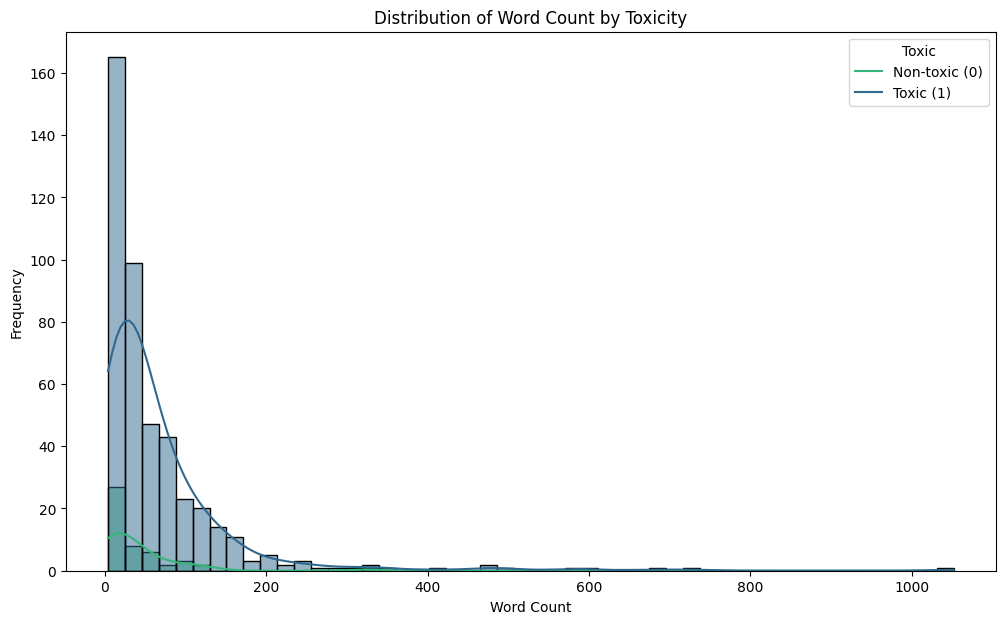

In [36]:
plt.figure(figsize=(12, 7))
sns.histplot(data=data, x='word_count', hue='toxic', bins=50, kde=True, palette='viridis')
plt.title('Distribution of Word Count by Toxicity')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.legend(title='Toxic', labels=['Non-toxic (0)', 'Toxic (1)'])
plt.show()

/tmp/ipykernel_16402/2433091854.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='toxic', y='word_count', palette='viridis')


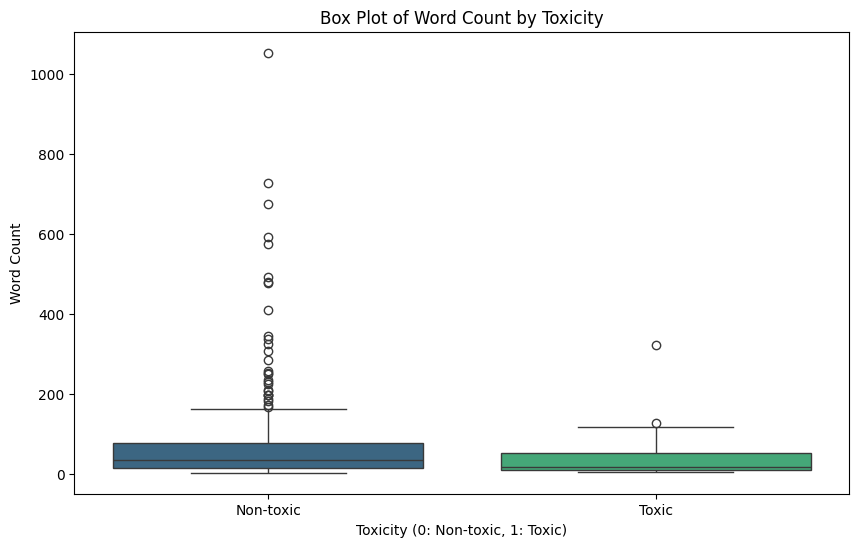

In [37]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='toxic', y='word_count', palette='viridis')
plt.title('Box Plot of Word Count by Toxicity')
plt.xlabel('Toxicity (0: Non-toxic, 1: Toxic)')
plt.ylabel('Word Count')
plt.xticks([0, 1], ['Non-toxic', 'Toxic'])
plt.show()

/tmp/ipykernel_16402/2992410900.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(x='toxic', y=data['toxic'].astype(float), data=data, palette='viridis', jitter=True)


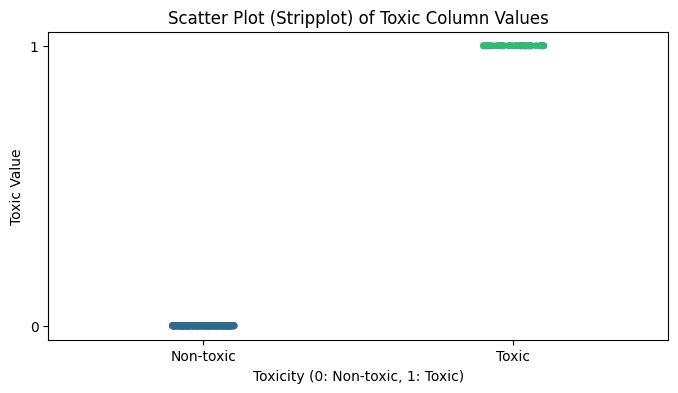

In [38]:
# plt.figure(figsize=(8, 4))
# sns.stripplot(x='toxic', y=data['toxic'].astype(float), data=data, palette='viridis', jitter=True)
# plt.title('Scatter Plot (Stripplot) of Toxic Column Values')
# plt.xlabel('Toxicity (0: Non-toxic, 1: Toxic)')
# plt.ylabel('Toxic Value')
# plt.xticks([0, 1], ['Non-toxic', 'Toxic'])
# plt.yticks([0, 1])
# plt.show()

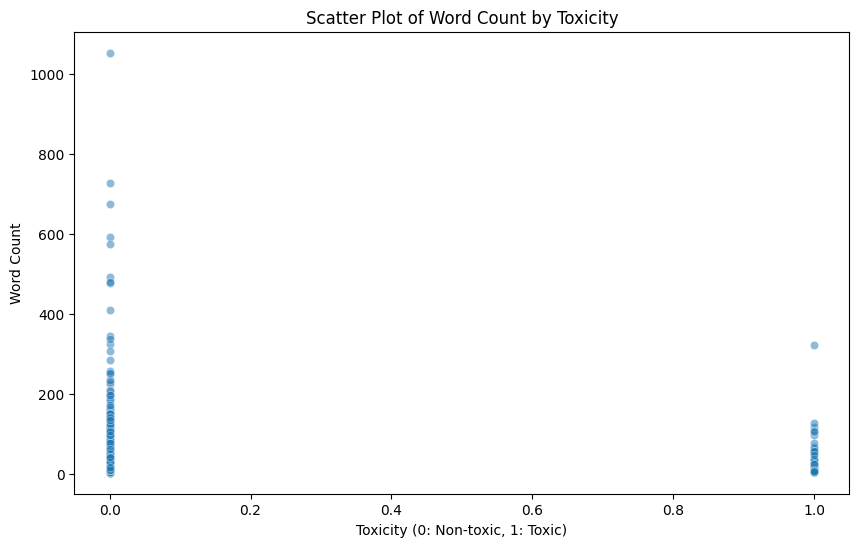

In [40]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='toxic', y='word_count', data=data, alpha=0.5)
plt.title('Scatter Plot of Word Count by Toxicity')
plt.xlabel('Toxicity (0: Non-toxic, 1: Toxic)')
plt.ylabel('Word Count')
plt.show()

/tmp/ipykernel_16402/1627679153.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='toxic', y='word_count', data=median_word_count, palette='viridis')


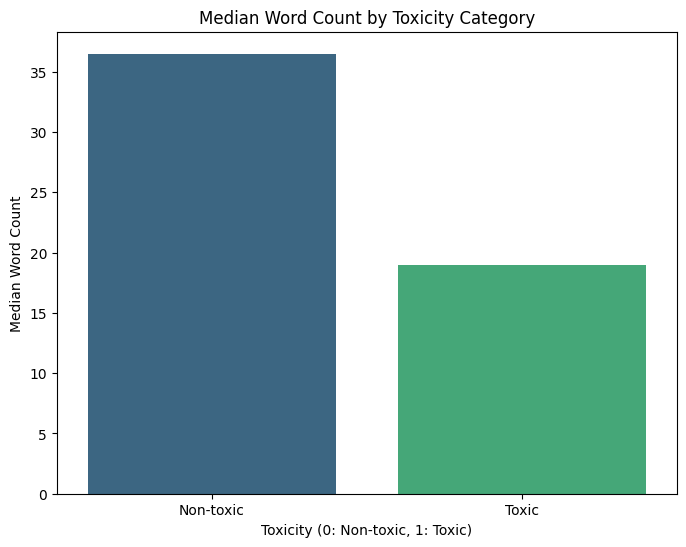

In [41]:
median_word_count = data.groupby('toxic')['word_count'].median().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(x='toxic', y='word_count', data=median_word_count, palette='viridis')
plt.title('Median Word Count by Toxicity Category')
plt.xlabel('Toxicity (0: Non-toxic, 1: Toxic)')
plt.ylabel('Median Word Count')
plt.xticks([0, 1], ['Non-toxic', 'Toxic'])
plt.show()

### Bigram Analysis and Visualization

Now, let's analyze bigrams (sequences of two words) in the `comment_text` to identify the most frequently occurring word pairs. We'll use `CountVectorizer` to extract bigrams and then visualize the top 25.

In [42]:
# Create a CountVectorizer to extract bigrams
bigram_vectorizer = CountVectorizer(tokenizer=spacy_tokenizer, ngram_range=(2, 2))

# Fit and transform the comment_text data to get bigram counts
X_bigrams = bigram_vectorizer.fit_transform(data['comment_text'])

# Get feature names (bigrams)
bigram_names = bigram_vectorizer.get_feature_names_out()

# Sum the counts of each bigram across all documents
bigram_counts = X_bigrams.sum(axis=0)

# Create a DataFrame of bigrams and their counts
bigram_df = pd.DataFrame({'bigram': bigram_names, 'count': bigram_counts.tolist()[0]})

# Sort by count in descending order and get the top 25
top_25_bigrams = bigram_df.sort_values(by='count', ascending=False).head(25)

display(top_25_bigrams)

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


,bigram,count
10689,talk page,33
4004,fair use,17
8009,personal attack,12
3527,edit war,11
242,2005 utc,9
10875,thank talk,7
5259,image copyright,7
3519,edit summary,7
11714,vertical align,7
13020,— precede,7


/tmp/ipykernel_16402/2558970612.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='count', y='bigram', data=top_25_bigrams, palette='viridis')


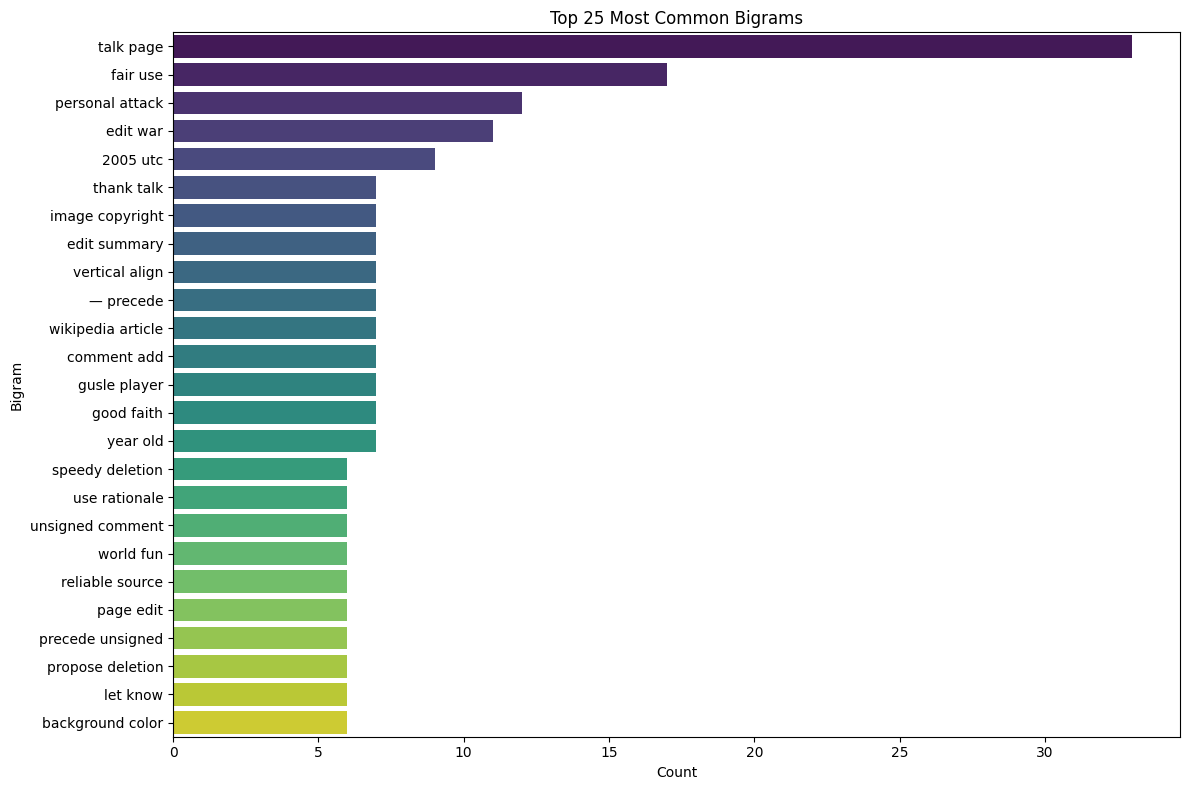

In [43]:
plt.figure(figsize=(12, 8))
sns.barplot(x='count', y='bigram', data=top_25_bigrams, palette='viridis')
plt.title('Top 25 Most Common Bigrams')
plt.xlabel('Count')
plt.ylabel('Bigram')
plt.tight_layout()
plt.show()

In [46]:
from sklearn.model_selection import train_test_split

X = data['comment_text'] # the features we want to analyze
ylabels = data['toxic'] # the labels, or answers, we want to test against

X_train, X_test, y_train, y_test = train_test_split(X, ylabels, test_size=0.2,stratify=ylabels)

In [ ]:
  !pip install langdetect -q

In [ ]:
from langdetect import detect

def is_english(text):
    try:
        return detect(text) == 'en'
    except:
        return False

# Apply the function to filter out non-English comments
data = data[data['comment_text'].apply(is_english)]

display(data.head())

,comment_text,toxic,word_count
0,Explanation\nWhy the edits made under my usern...,0.0,43
1,D'aww! He matches this background colour I'm s...,0.0,17
2,"Hey man, I'm really not trying to edit war. It...",0.0,42
3,\nMore\nI can't make any real suggestions on i...,0.0,111
4,"You, sir, are my hero. Any chance you remember...",0.0,13


In [18]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression()

In [19]:
X_train_vetcors= count_vector.fit_transform(X_train)
X_test_vetcors= count_vector.transform(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [20]:
X_train_vetcors.shape

(399, 4139)

In [21]:
X_test_vetcors.shape

(100, 4139)

In [22]:
X_train_vetcors.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [3, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [24]:
classifier.fit(X_train_vetcors,y_train)

LogisticRegression()

In [25]:
predicted = classifier.predict(X_test_vetcors)
print("Logistic Regression Accuracy:",metrics.accuracy_score(y_test, predicted))
print("Logistic Regression Precision:",metrics.precision_score(y_test, predicted))
print("Logistic Regression Recall:",metrics.recall_score(y_test, predicted))

Logistic Regression Accuracy: 0.92
Logistic Regression Precision: 1.0
Logistic Regression Recall: 0.2


In [26]:
tfidf_vector = TfidfVectorizer(tokenizer = spacy_tokenizer)
X_train_vetcors= tfidf_vector.fit_transform(X_train)
X_test_vetcors= tfidf_vector.transform(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [27]:
classifier = LogisticRegression()
classifier.fit(X_train_vetcors,y_train)
predicted = classifier.predict(X_test_vetcors)
print("Logistic Regression Accuracy:",metrics.accuracy_score(y_test, predicted))
print("Logistic Regression Precision:",metrics.precision_score(y_test, predicted))
print("Logistic Regression Recall:",metrics.recall_score(y_test, predicted))

Logistic Regression Accuracy: 0.9
Logistic Regression Precision: 0.0
Logistic Regression Recall: 0.0


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [29]:
data_without_toxic = data[data['toxic'] == 0]
data_without_toxic.shape

(450, 2)